# Predicting Ratings for New Recipes: Item Cold-Start on Food.com

CSE 158/258 Assignment 2. When a recipe has just been posted, nobody has rated it yet, so a recommender cannot learn anything about it from ratings. We ask: **given a user and a recipe with no ratings in the training data, how well can we predict the rating the user will give it, using only the user's history and the recipe's content?**

**Contents**
1. Predictive task
2. Data, exploratory analysis and preprocessing
3. Modeling
4. Evaluation
5. Related work
6. Conclusion

Everything the notebook runs is in it: data loading, the time-aware feature code (Section 3.2), the evaluation code (Section 4) and all models; the chart helpers are in the first code cells. Its inputs are the cleaned data written by `preprocess.py` (`data_clean/`) and the original Food.com files (`PP_recipes.csv`, and in Section 2.1 the authors' split). Hyperparameters were chosen on the validation split in the development notebooks (`03_baselines_rating.ipynb`, `04_models_rating.ipynb`); here they are fixed. Running it from the top takes about 4 minutes.

In [1]:
import ast
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Chart helpers (styling only): bars with 95% confidence-interval whiskers for model comparisons, grouped bars, a calibration curve and a correlation heatmap.

In [2]:
# categorical colors in fixed order; GRAY for reference lines, INK for secondary text

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUE, ORANGE = SERIES[0], SERIES[1]
GRAY, INK = "#8a8984", "#52514e"

def setup():
    plt.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
        "grid.color": "#e6e5e0", "axes.axisbelow": True, "lines.linewidth": 2,
        "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110,
    })

def _label(name):
    """'B2 user features' -> 'B2\\nuser features' so long model names fit under a bar."""
    return name.replace(" ", "\n", 1)

def _reference(ax, ref, ref_label):
    if ref is not None:
        ax.axhline(ref, color=GRAY, linestyle="--", linewidth=1)
        ax.text(ax.get_xlim()[1], ref, f" {ref_label}", va="center", ha="left", fontsize=8, color=INK)

def bars(ax, names, values, low=None, high=None, ref=None, ref_label="random", fmt="{:.3f}", title=None, ylabel=None,
         short=False):
    """Vertical bars (one per model) with optional 95% CI whiskers and value labels above each bar.
    short=True labels each bar with the model code only ('B2'), for narrow panels."""
    values = np.asarray(values, float)
    x = np.arange(len(values))
    err = None if low is None else [values - np.asarray(low, float), np.asarray(high, float) - values]
    ax.bar(x, values, width=0.6, color=BLUE, yerr=err,
           error_kw=dict(ecolor=INK, elinewidth=1.2, capsize=4))
    top = values if high is None else np.maximum(values, np.asarray(high, float))
    pad = 0.03 * np.nanmax(np.abs(top))
    for xi, v, t in zip(x, values, top):
        ax.text(xi, max(t, 0) + pad, fmt.format(v), ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(x, [n.split(" ")[0] if short else _label(n) for n in names], fontsize=8)
    # y range covers the whiskers too, so a CI that crosses 0 stays visible
    bottom = np.nanmin(values if low is None else np.minimum(values, np.asarray(low, float)))
    upper = np.nanmax(top) * 1.18 if np.nanmax(top) > 0 else 0.15 * abs(bottom)
    ax.set_ylim(min(0, bottom - 0.08 * (upper - bottom)) if bottom < 0 else 0, upper)
    _reference(ax, ref, ref_label)
    if title:
        ax.set_title(title)
    if ylabel:
        ax.set_ylabel(ylabel)

def metric_bars(table, metrics, refs=None, suptitle=None, low="{} low", high="{} high", width=4.2):
    """One bar panel per metric; `table` has a row per model and columns metric, '<metric> low', '<metric> high'."""
    refs = refs or {}
    fig, axes = plt.subplots(1, len(metrics), figsize=(width * len(metrics), 3.6), squeeze=False)
    for ax, m in zip(axes[0], metrics):
        bars(ax, table.index, table[m], table[low.format(m)], table[high.format(m)], ref=refs.get(m), title=m, short=True)
    if suptitle:
        fig.suptitle(suptitle, fontweight="bold")
    fig.text(0.5, 0.01, "   ".join(table.index), ha="center", fontsize=8, color=INK)   # code -> model name
    plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

def grouped_bars(ax, categories, series, ylabel, title, fmt="{:.2f}"):
    """One group of bars per category, one bar per model (series: model -> values), value above each bar."""
    x, w = np.arange(len(categories)), 0.8 / len(series)
    for k, (color, (name, values)) in enumerate(zip(SERIES, series.items())):
        xs = x + (k - (len(series) - 1) / 2) * w
        ax.bar(xs, values, w * 0.92, color=color, label=name)
        for xi, v in zip(xs, values):
            ax.text(xi, v, fmt.format(v), ha="center", va="bottom", fontsize=7, color=INK)
    ax.set_xticks(x, categories)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.15 * (hi - lo))          # room for a one-row legend above the bars
    ax.legend(frameon=False, fontsize=8, ncol=len(series), loc="upper left")

def calibration(ax, y, scores, n_bins=10, title=None, base_rate=True):
    """Reliability curve: mean prediction vs. observed positive share in equal-size bins of the prediction
    (scores: model -> probabilities). A calibrated model lies on the diagonal."""
    ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1, label="perfect calibration")
    lo = 1.0
    for color, (name, s) in zip(SERIES, scores.items()):
        bins = np.array_split(np.argsort(s), n_bins)
        pred, obs = [s[b].mean() for b in bins], [y[b].mean() for b in bins]
        ax.plot(pred, obs, "o-", color=color, label=name, markersize=5)
        lo = min(lo, *pred, *obs)
    ax.set_xlim(lo - 0.05, 1); ax.set_ylim(lo - 0.05, 1)
    if base_rate:
        ax.axhline(np.mean(y), color=INK, linestyle=":", linewidth=1)
        ax.text(lo - 0.04, np.mean(y) + 0.01, f"actual positive share {np.mean(y):.1%}", fontsize=8, color=INK)
    ax.set_xlabel("mean predicted probability")
    ax.set_ylabel("observed share of positives")
    ax.grid(True, axis="both")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    if title:
        ax.set_title(title)

def heatmap(ax, corr, title=None, fmt="{:.2f}"):
    """Correlation matrix as a diverging heatmap (-1 blue, 0 white, +1 red) with the value in each cell.
    Returns the image, for a colorbar."""
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(corr.shape[1]), corr.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(corr.shape[0]), corr.index, fontsize=8)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            v = corr.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else INK)
    ax.grid(False)
    if title:
        ax.set_title(title)
    return im

def compare_medians(a, b, labels, title):
    """Small multiples: the median of each feature in two row sets (e.g. training vs evaluation rows)."""
    cols = list(a.index)
    fig, axes = plt.subplots(1, len(cols), figsize=(2.3 * len(cols), 3), squeeze=False)
    for ax, c in zip(axes[0], cols):
        v = [a[c], b[c]]
        ax.bar([0, 1], v, width=0.6, color=[BLUE, ORANGE])
        for xi, vi in enumerate(v):
            ax.text(xi, vi, f"{vi:.3g}", ha="center", va="bottom", fontsize=8, color=INK)
        ax.set_xticks([0, 1], labels, fontsize=8)
        ax.set_title(c, fontsize=9)
        ax.set_ylim(0, max(v) * 1.2)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout(); plt.show()

setup()

## 1. Predictive task

| | |
|---|---|
| **Input** | `(user_id, recipe_id)` and the review date |
| **Output (main task)** | the rating, a number in [1, 5] (predictions are clipped to this range) |
| **Output (supplementary)** | P(rating == 5), a number in [0, 1] |
| **Setting** | **item cold-start**: we evaluate only on reviews of recipes that have **no reviews in the data the model is trained on** (`cold == 1`). Every user has at least 3 earlier ratings. |
| **Main metric** | **MSE** (the course's rating-prediction metric), with RMSE and MAE |
| **Supplementary metric** | **AUC** for `rating == 5` (80% of the cold test rows are 5 stars, so accuracy would be meaningless), and log loss |
| **Ranking** | Hit@10 / NDCG@10: each 5-star cold test review is ranked against 99 cold recipes the user never reviewed |

A cold recipe has no ratings, so an ID-only model has nothing to learn about it. The recipe id is therefore used only to **look up the recipe's content** (tags, nutrition, steps, text, author), and the user id to look up the user's **earlier** ratings.

**Baselines.** B0 global mean; B1 the course's bias model $\alpha + \beta_u + \beta_i$ (ID only); B2 ridge regression on user-history features (user only); B3 ridge regression on TF-IDF similarity between the recipe and the user's past recipes (content only).

**How we check that the predictions are valid.** A strict time split (no future information in any feature), a single evaluation of the test split after all choices were made on validation, 95% confidence intervals from a bootstrap over **users**, paired comparisons against B2, errors broken down by the true rating, and cold vs. warm rows.

## 2. Data, exploratory analysis and preprocessing

**Source.** Food.com reviews and recipes released by Majumder et al. (2019): 1,132,367 reviews by 226,570 users of 231,637 recipes, 2000–2018. We use `RAW_interactions.csv` (user, recipe, date, rating), `RAW_recipes.csv` (minutes, tags, nutrition, steps, ingredients, description, contributor, submission date) and `PP_recipes.csv` (58 cooking techniques, calorie level, and the 178,265 recipes the authors kept).

The constants below are used throughout the notebook; `load_data` reads the three cleaned splits and the recipe table (parsing the list columns and adding the 58 techniques and calorie level).

In [3]:
ROOT = Path("..").resolve()     # the repository root (this notebook is in notebooks/)

CLEAN = ROOT / "data_clean"
RAW = ROOT / "dataset" if (ROOT / "dataset").is_dir() else ROOT.parent / "Assignment2" / "dataset_old"
N_TAGS = 300          # most common tags kept as multi-hot columns / match vocabulary
N_INGREDIENTS = 300   # most common ingredients kept for matching
KNN_KS = (5, 10, 20, 50)
SMOOTH_M = 10         # pseudo-count pulling small-sample 5-star shares towards the global share
MIN_PRIOR = 3         # training rows need at least this many earlier ratings by the user

NUTRITION_COLS = ["calories", "total_fat_pdv", "sugar_pdv", "sodium_pdv",
                  "protein_pdv", "saturated_fat_pdv", "carbohydrates_pdv"]

def load_data():
    """Cleaned splits and the recipe table (indexed by recipe id, list columns parsed)."""
    splits = {name: pd.read_csv(CLEAN / f"interactions_{name}.csv", parse_dates=["date"])
              for name in ("train", "validation", "test")}
    recipes = pd.read_csv(CLEAN / "RAW_recipes_clean.csv", parse_dates=["submitted"])
    recipes["description"] = recipes.description.fillna("")
    pp = pd.read_csv(RAW / "PP_recipes.csv", usecols=["id", "techniques", "calorie_level"])
    recipes = recipes.merge(pp, on="id").set_index("id")
    for col in ("tags", "ingredients", "techniques"):
        recipes[col] = recipes[col].map(ast.literal_eval)
    return splits, recipes

### 2.1 Why we re-split the data by time

The authors also provide a train/validation/test split. Our features summarize each user's **past** ratings, which is only honest if "past" means *before* the review being predicted.

official split: 82.7% of test users have training reviews dated AFTER their test review


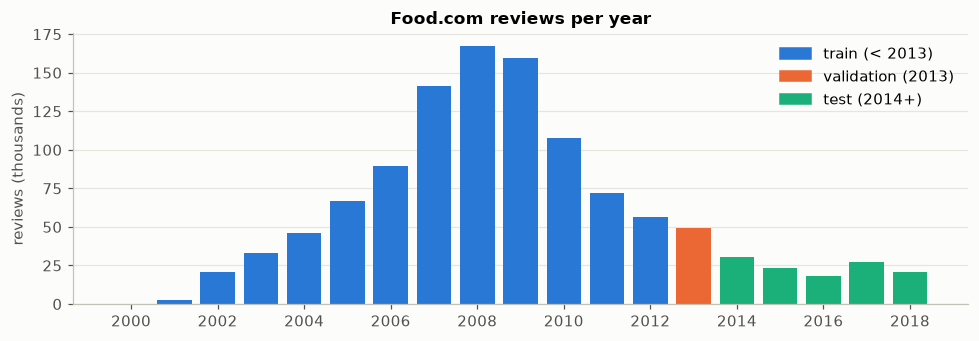

In [4]:
splits, recipes = load_data()
train, valid, test = splits["train"], splits["validation"], splits["test"]

off_train = pd.read_csv(RAW / "interactions_train.csv", parse_dates=["date"])
off_test = pd.read_csv(RAW / "interactions_test.csv", parse_dates=["date"])
last_train_review = off_train.groupby("user_id").date.max()
sees_future = (last_train_review.reindex(off_test.user_id).values > off_test.date.values).mean()
print(f"official split: {sees_future:.1%} of test users have training reviews dated AFTER their test review")

raw = pd.read_csv(RAW / "RAW_interactions.csv", usecols=["date"], parse_dates=["date"])
per_year = raw.groupby(raw.date.dt.year).size()
split_color = [SERIES[0] if y < 2013 else SERIES[1] if y < 2014 else SERIES[2] for y in per_year.index]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(per_year.index, per_year / 1000, color=split_color, width=0.8)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in SERIES[:3]],
          ["train (< 2013)", "validation (2013)", "test (2014+)"], frameon=False)
ax.set_xticks(per_year.index[::2]); ax.set_ylabel("reviews (thousands)"); ax.set_title("Food.com reviews per year")
plt.tight_layout(); plt.show()

For most test users the official training file contains reviews written *after* the review we would predict, so user-history features would see the future. We therefore rebuilt the split from all reviews with a **global time cut**: train before 2013, validation 2013, test 2014–2018. Activity on the site collapsed after 2008, so the cut is a trade-off between training data and evaluation rows: a 2015/2016 cut left only 894 cold test rows, while 2013/2014 gives 4,099 and keeps 94% of the training rows. The cut was chosen for sample size before any model was compared, and was not changed afterwards.

### 2.2 Preprocessing (`preprocess.py`)

| Step | Decision | Reason |
|---|---|---|
| rating = 0 | dropped (46,257 reviews) | a review without stars has no label |
| duplicates | one review per user–recipe pair (the earliest) | |
| users | keep users with ≥ 3 ratings before 2013 (27,327 users) | the task is item cold-start; the filter uses only the training period |
| cold label | for each validation/test row, `n_fit` = reviews of the recipe in the data the model is fit on (train for validation, train + validation for test); `cold = 1` when 0 | defines the evaluation rows |
| `minutes`, nutrition | impossible values (2,147,483,647 minutes, 434,360 calories) clipped at the training 99th percentile, with flags | thresholds use training recipes only |
| user features | **never** taken from the authors' `PP_users.csv` | it summarizes all years, including the future |

In [5]:
for name, d in splits.items():
    extra = f"; cold rows {d.cold.sum():,} ({d[d.cold == 1].user_id.nunique()} users)" if "cold" in d else ""
    print(f"{name:>10}: {len(d):,} reviews, {d.date.min():%Y-%m-%d} to {d.date.max():%Y-%m-%d}{extra}")
user_counts = train.user_id.value_counts()
print(f"long tail: the top 1% of users wrote {user_counts.head(len(user_counts) // 100).sum() / len(train):.1%} of training reviews")

     train: 683,996 reviews, 2000-02-25 to 2012-12-31
validation: 22,933 reviews, 2013-01-01 to 2013-12-31; cold rows 6,410 (859 users)
      test: 22,224 reviews, 2014-01-01 to 2018-12-18; cold rows 4,099 (857 users)
long tail: the top 1% of users wrote 32.4% of training reviews


### 2.3 Ratings are almost always 5 stars

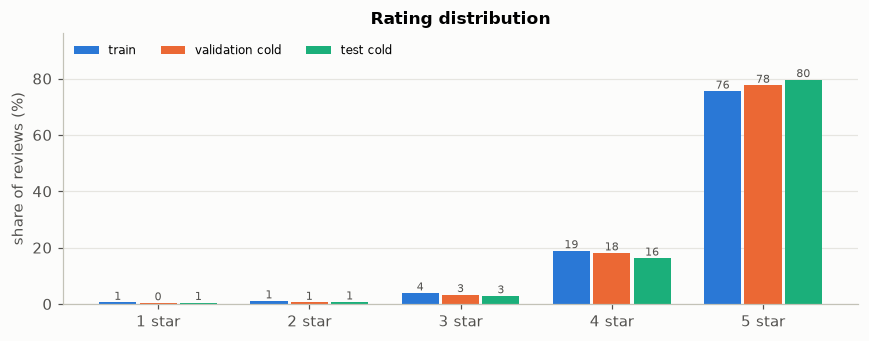

predicting the training mean (4.677) on test cold rows: MSE 0.362; variance of their ratings: 0.358


In [6]:
test_cold_rows = test[test.cold == 1]
dist = {name: d.rating.value_counts(normalize=True).reindex(range(1, 6), fill_value=0) * 100
        for name, d in [("train", train), ("validation cold", valid[valid.cold == 1]), ("test cold", test_cold_rows)]}
fig, ax = plt.subplots(figsize=(8, 3.2))
grouped_bars(ax, [f"{r} star" for r in range(1, 6)], dist, "share of reviews (%)", "Rating distribution", fmt="{:.0f}")
plt.tight_layout(); plt.show()

mean_rating = train.rating.mean()
print(f"predicting the training mean ({mean_rating:.3f}) on test cold rows: MSE {((test_cold_rows.rating - mean_rating) ** 2).mean():.3f}; "
      f"variance of their ratings: {test_cold_rows.rating.var(ddof=0):.3f}")

About 80% of cold test ratings are 5 stars and only 4% are 1–3 stars. Predicting the training mean already gives an MSE almost equal to the variance, so **improvements in MSE will be small and driven by a few low ratings**. This shapes the evaluation: every result is reported with a confidence interval, errors are broken down by true rating, and the supplementary binary task (5 stars or not, AUC) measures whether a model can *rank* reviews even when MSE barely moves. (`rating >= 4` was not used as the binary label: 95% of rows would be positive.)

A long tail of activity (the top 1% of users wrote about a third of the training reviews) means a few heavy users would dominate training; each training row is weighted by $1/\sqrt{n_u}$, and the bootstrap resamples users rather than rows.

## 3. Modeling

### 3.1 Training rows that look like cold-start

Every recipe in the training split has reviews, so there are no cold rows to train on. We use **pseudo-cold rows**: the reviews written on the first day a recipe was reviewed. When they were written the recipe had no reviews, exactly like a cold test row. We keep rows whose user already had ≥ 3 earlier ratings (as every evaluation user does).

In [7]:
def pseudo_cold_rows(history):
    """Reviews written on the first day their recipe was reviewed: at that time the recipe had no reviews."""
    first_day = history.groupby("recipe_id").date.transform("min")
    rows = history[history.date == first_day].copy()
    rows["y"] = (rows.rating == 5).astype(int)
    return rows

def training_weights(users):
    """1 / sqrt(rows per user), so heavy users do not dominate training."""
    counts = pd.Series(users).map(pd.Series(users).value_counts())
    return 1 / np.sqrt(counts.values)

### 3.2 Features

All features are looked up from the ids and computed from reviews dated **strictly before** the row's date (training rows see their own past; validation rows see train; test rows see train + validation). No rating statistic of the recipe itself is used, since a cold recipe has none.

| Group | Content |
|---|---|
| **A** recipe content | log minutes, steps, ingredients, nutrition, calorie level, cleaning flags, submission year, description length, top-300 tags (multi-hot), recipe age at review time |
| **B** user history | number of past ratings, mean rating (raw and smoothed), standard deviation, 5-star share (raw and smoothed) |
| **C** user × recipe match | similarity (cosine, Jaccard, max) of the recipe to the user's past and 5-star recipes over tags, ingredients, techniques; the user's ratings of the k most similar past recipes; TF-IDF similarity of the recipe text to the user's past recipes |
| **D** author | the contributor's other recipes: number of earlier reviews, smoothed mean rating and 5-star share, number of recipes |

**How the features stay in the past.** Each user's reviews are sorted by date. For a row dated *d*, `np.searchsorted` gives the number *k* of the user's reviews strictly before *d*; prefix sums over the sorted reviews (`_cumsum0`) then give the count, mean rating, 5-star share and content profile of exactly those *k* reviews, for all rows of the user at once, and similarities to reviews on or after *d* are masked out. The same functions therefore serve training rows (history = train, each row sees its own past), validation rows (history = train) and test rows (history = train + validation).

**A. Recipe content**: one row per recipe, independent of any rating. `content_matrix` is the binary recipe × (top-300 tags | top-300 ingredients | 58 techniques) matrix that the match features compare.

In [8]:
def top_vocab(lists, n):
    return pd.Series([x for xs in lists for x in xs]).value_counts().index[:n].tolist()

def multi_hot(lists, vocab):
    """Sparse 0/1 matrix (len(lists) x len(vocab)); items outside the vocabulary are ignored."""
    col = {v: j for j, v in enumerate(vocab)}
    rows, cols = [], []
    for i, xs in enumerate(lists):
        for j in {col[x] for x in xs if x in col}:
            rows.append(i)
            cols.append(j)
    return sparse.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(len(lists), len(vocab)))

def recipe_features(recipes, tag_vocab):
    """Group A: one row per recipe."""
    f = pd.DataFrame(index=recipes.index)
    f["log_minutes"] = np.log1p(recipes.minutes)
    for c in ["minutes_missing", "minutes_clipped", "n_steps", "n_ingredients",
              "nutrition_extreme", "calories_zero", "has_description"]:
        f[c] = recipes[c]
    for c in NUTRITION_COLS:
        f[f"log_{c}"] = np.log1p(recipes[c])
    for level in (0, 1, 2):
        f[f"calorie_level_{level}"] = (recipes.calorie_level == level).astype(int)
    f["submitted_year"] = recipes.submitted.dt.year
    f["description_words"] = recipes.description.str.split().str.len()
    tags = pd.DataFrame(multi_hot(recipes.tags.tolist(), tag_vocab).toarray().astype(np.uint8),
                        index=recipes.index, columns=[f"tag_{t}" for t in tag_vocab])
    return pd.concat([f, tags], axis=1)

def content_matrix(recipes, tag_vocab, ingredient_vocab):
    """Binary recipe x (tags | ingredients | techniques) matrix and the column slice of each space."""
    blocks = [multi_hot(recipes.tags.tolist(), tag_vocab),
              multi_hot(recipes.ingredients.tolist(), ingredient_vocab),
              sparse.csr_matrix(np.array(recipes.techniques.tolist(), dtype=np.float32))]
    edges = np.cumsum([0] + [b.shape[1] for b in blocks])
    spaces = {"tags": slice(edges[0], edges[1]), "ingr": slice(edges[1], edges[2]),
              "tech": slice(edges[2], edges[3]), "all": slice(0, edges[3])}
    return sparse.hstack(blocks).tocsr(), spaces

**B. User history and C. user × recipe match.** For every space (tags, ingredients, techniques, all): cosine and Jaccard similarity between the recipe and the user's profile (sum of past recipes) and liked profile (5-star recipes), the maximum Jaccard similarity to one past recipe, and for the *K* most similar past recipes (*K* = 5, 10, 20, 50) the similarity-weighted 5-star share and mean rating. Also the distance of the recipe's minutes and calories to the user's average.

In [9]:
def _cumsum0(a):
    """Cumulative sums with a leading zero row: _cumsum0(a)[k] = sum of the first k rows."""
    return np.concatenate([np.zeros((1,) + a.shape[1:], dtype=a.dtype), np.cumsum(a, axis=0)])

def _cosine(a, b):
    norm = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    return np.divide((a * b).sum(1), norm, out=np.full(len(a), np.nan), where=norm > 0)

def _jaccard(a, b):
    """Row-wise Jaccard of the non-zero sets of a and b."""
    a, b = a > 0, b > 0
    inter = (a & b).sum(1)
    union = a.sum(1) + b.sum(1) - inter
    return np.divide(inter, union, out=np.full(len(a), np.nan), where=union > 0)

def history_features(rows, history, recipes, content):
    """Groups B and C for each row, from the user's reviews in `history` strictly before the row's date."""
    M, spaces = content
    pos = pd.Series(np.arange(len(recipes)), index=recipes.index)
    log_minutes = np.log1p(recipes.minutes.values)
    log_calories = np.log1p(recipes.calories.values)

    h = history.sort_values(["user_id", "date"])
    h_date, h_pos = h.date.values, pos[h.recipe_id].values
    h_y, h_rating = (h.rating.values == 5).astype(np.float32), h.rating.values.astype(np.float32)
    p0, mu0 = h_y.mean(), h_rating.mean()
    users, starts, counts = np.unique(h.user_id.values, return_index=True, return_counts=True)
    bounds = dict(zip(users, zip(starts, starts + counts)))

    r_date, r_pos = rows.date.values, pos[rows.recipe_id].values
    out = {}
    def put(name, idx, values):
        out.setdefault(name, np.full(len(rows), np.nan, dtype=np.float32))[idx] = values

    for user, idx in rows.groupby("user_id").indices.items():
        s, e = bounds.get(user, (0, 0))
        k = np.searchsorted(h_date[s:e], r_date[idx], side="left")   # reviews strictly before each row
        y, rating = h_y[s:e], h_rating[s:e]

        # B. user history
        n, n5 = k.astype(np.float32), _cumsum0(y)[k]
        mean = np.divide(_cumsum0(rating)[k], n, out=np.full(len(k), np.nan, dtype=np.float32), where=n > 0)
        sq = np.divide(_cumsum0(rating ** 2)[k], n, out=np.full(len(k), np.nan, dtype=np.float32), where=n > 0)
        put("u_n", idx, n)
        put("u_rate", idx, np.divide(n5, n, out=np.full(len(k), np.nan, dtype=np.float32), where=n > 0))
        put("u_rate_smooth", idx, (n5 + SMOOTH_M * p0) / (n + SMOOTH_M))
        put("u_mean", idx, mean)
        put("u_mean_smooth", idx, (_cumsum0(rating)[k] + SMOOTH_M * mu0) / (n + SMOOTH_M))
        put("u_std", idx, np.sqrt(np.maximum(sq - mean ** 2, 0)))

        # C. numeric preference: distance to the user's average past recipe
        lm, lc = log_minutes[h_pos[s:e]], log_calories[h_pos[s:e]]
        for name, past, target in [("minutes", lm, log_minutes[r_pos[idx]]), ("calories", lc, log_calories[r_pos[idx]])]:
            avg = np.divide(_cumsum0(past)[k], n, out=np.full(len(k), np.nan), where=n > 0)
            put(f"m_{name}_diff", idx, np.abs(target - avg))

        # C. content match: profile similarity and k-nearest past recipes
        H = M[h_pos[s:e]].toarray()            # user's past recipes (in date order)
        T = M[r_pos[idx]].toarray()            # target recipes
        profile, liked = _cumsum0(H)[k], _cumsum0(H * y[:, None])[k]
        future = np.arange(e - s)[None, :] >= k[:, None]
        for space, sl in spaces.items():
            t, hs = T[:, sl], H[:, sl]
            put(f"m_{space}_cos", idx, _cosine(profile[:, sl], t))
            put(f"m_{space}_cos_liked", idx, _cosine(liked[:, sl], t))
            put(f"m_{space}_jaccard", idx, _jaccard(profile[:, sl], t))

            inter = t @ hs.T
            union = t.sum(1)[:, None] + hs.sum(1)[None, :] - inter
            sim = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
            sim[future] = -1                   # never look at reviews on or after the row's date
            has_past = k > 0
            put(f"m_{space}_max_sim", idx, np.where(has_past, sim.max(1, initial=-1), np.nan))
            order = np.argsort(-sim, axis=1, kind="stable")   # ties: earlier review first
            for K in KNN_KS:
                top = order[:, :K]
                w = np.clip(np.take_along_axis(sim, top, 1), 0, None)
                den = w.sum(1)
                for suffix, target in [("", y), ("_rating", rating)]:
                    put(f"m_{space}_knn{K}{suffix}", idx,
                        np.divide((w * target[top]).sum(1), den, out=np.full(len(k), np.nan), where=den > 0))

    return pd.DataFrame(out, index=rows.index)

**D. Author**: the contributor's other recipes, using reviews dated before the row (`merge_asof` with `allow_exact_matches=False`). Shares and means are smoothed towards the global value with 10 pseudo-reviews.

In [10]:
def author_features(rows, history, recipes):
    """Group D: the recipe author's other recipes, using reviews strictly before the row's date."""
    author = recipes.contributor_id
    h = history.assign(a=author.reindex(history.recipe_id).values, y=(history.rating == 5).astype(int))
    p0, mu0 = h.y.mean(), h.rating.mean()
    daily = h.groupby(["a", "date"]).agg(n=("y", "size"), n5=("y", "sum"), sr=("rating", "sum")).reset_index()
    daily[["a_n", "a_n5", "a_sr"]] = daily.groupby("a")[["n", "n5", "sr"]].cumsum()

    # recipes the author had submitted before the row's date
    sub = recipes.reset_index()[["contributor_id", "submitted"]].rename(columns={"contributor_id": "a", "submitted": "date"})
    sub = sub.sort_values("date")
    sub["a_recipes"] = sub.groupby("a").cumcount() + 1

    left = pd.DataFrame({"date": rows.date.values, "a": author.reindex(rows.recipe_id).values,
                         "_row": np.arange(len(rows))}).sort_values("date")
    left = pd.merge_asof(left, daily[["a", "date", "a_n", "a_n5", "a_sr"]].sort_values("date"),
                         on="date", by="a", allow_exact_matches=False)
    left = pd.merge_asof(left, sub, on="date", by="a", allow_exact_matches=False)
    left = left.sort_values("_row")
    a_n, a_n5, a_sr = (left[c].fillna(0).values for c in ("a_n", "a_n5", "a_sr"))
    return pd.DataFrame({
        "a_n": a_n,
        "a_rate_smooth": (a_n5 + SMOOTH_M * p0) / (a_n + SMOOTH_M),
        "a_mean_smooth": (a_sr + SMOOTH_M * mu0) / (a_n + SMOOTH_M),
        "a_recipes": left.a_recipes.fillna(0).values,
    }, index=rows.index)

**TF-IDF similarity** (part of C): cosine between the recipe's text (name, tags, ingredients, description, steps) and the centroid of the user's earlier recipes, all of them and the 5-star ones. `_prefix_norm2` computes the norm of every prefix centroid from the Gram matrix, so no centroid is formed explicitly.

In [11]:
def tfidf_matrix(recipes, min_df=5, max_features=50000):
    """L2-normalized TF-IDF of each recipe's name, tags, ingredients, description and steps."""
    text = (recipes.name.fillna("") + " " + recipes.tags.str.join(" ") + " " + recipes.ingredients.str.join(" ")
            + " " + recipes.description + " " + recipes.steps.fillna(""))
    vectorizer = TfidfVectorizer(min_df=min_df, max_features=max_features, stop_words="english",
                                 sublinear_tf=True, dtype=np.float32)
    return vectorizer.fit_transform(text.values)

def _prefix_norm2(H, block=1024):
    """||sum of the first k rows of H||^2 for k = 0..n, from the Gram matrix computed in row blocks."""
    n = H.shape[0]
    cross = np.zeros(n)                        # cross[j] = H_j . (H_0 + ... + H_{j-1})
    diag = np.asarray(H.multiply(H).sum(1)).ravel()
    for start in range(0, n, block):
        G = (H[start:start + block] @ H[:start + block].T).toarray()
        cross[start:start + block] = np.tril(G, k=start - 1).sum(1)   # columns before each row
    return np.concatenate([[0], np.cumsum(2 * cross + diag)])

def tfidf_features(rows, history, recipes, X):
    """Cosine between each row's recipe and the TF-IDF centroid of the user's earlier recipes:
    all of them (t_cos_all), the 5-star ones (t_cos_liked), and the others (t_cos_other)."""
    pos = pd.Series(np.arange(len(recipes)), index=recipes.index)
    h = history.sort_values(["user_id", "date"])
    h_date, h_pos, h_y = h.date.values, pos[h.recipe_id].values, (h.rating.values == 5)
    users, starts, counts = np.unique(h.user_id.values, return_index=True, return_counts=True)
    bounds = dict(zip(users, zip(starts, starts + counts)))
    r_date, r_pos = rows.date.values, pos[rows.recipe_id].values
    t_norm = np.sqrt(np.asarray(X.multiply(X).sum(1)).ravel())

    out = {name: np.full(len(rows), np.nan, dtype=np.float32) for name in ("t_cos_all", "t_cos_liked", "t_cos_other")}
    for user, idx in rows.groupby("user_id").indices.items():
        s, e = bounds.get(user, (0, 0))
        if e == s:
            continue
        k = np.searchsorted(h_date[s:e], r_date[idx], side="left")   # reviews strictly before each row
        H = X[h_pos[s:e]]
        S = (X[r_pos[idx]] @ H.T).toarray()                          # target . each past recipe
        S[np.arange(e - s)[None, :] >= k[:, None]] = 0               # never look at reviews on or after the row's date
        y = h_y[s:e]
        for name, mask in [("t_cos_all", np.ones(e - s, bool)), ("t_cos_liked", y), ("t_cos_other", ~y)]:
            dot = S[:, mask].sum(1)
            norm = np.sqrt(_prefix_norm2(H[np.where(mask)[0]])[np.cumsum(np.concatenate([[0], mask]))[k]])
            denom = norm * t_norm[r_pos[idx]]
            out[name][idx] = np.divide(dot, denom, out=np.full(len(idx), np.nan), where=denom > 0)
    return pd.DataFrame(out, index=rows.index)

**Relative versions and assembly.** `relative_features` re-expresses the k-NN features relative to the user (motivated in Section 3.3); `build_features` joins all groups. The vectorized feature code was checked against a slow row-by-row recomputation (200 rows, 0 mismatches).

In [12]:
def relative_features(f):
    """Group C relative to the user. The raw k-NN features are almost the user's own average (Spearman 0.97
    between m_tags_knn50_rating and u_mean), so they repeat group B. Subtracting the user's average keeps only
    how this kind of recipe differs from what the user usually gives:
      m_<space>_knn<K>_rating_dev = k-NN mean rating   - u_mean
      m_<space>_knn<K>_dev        = k-NN 5-star share  - u_rate
      t_cos_diff                  = t_cos_liked - t_cos_all  (closer to loved recipes than to the usual ones)"""
    out = {}
    for c in f.columns:
        m = re.fullmatch(r"(m_\w+_knn\d+)(_rating)?", c)
        if m:
            out[c + "_dev"] = f[c] - (f.u_mean if m.group(2) else f.u_rate)
    if "t_cos_liked" in f:
        out["t_cos_diff"] = f.t_cos_liked - f.t_cos_all
    return pd.DataFrame(out, index=f.index)

def build_features(rows, history, recipes, content, recipe_feats=None, tfidf=None):
    """All feature groups for `rows`, using `history` strictly before each row's date."""
    parts = [history_features(rows, history, recipes, content),
             author_features(rows, history, recipes),
             pd.DataFrame({"recipe_age": (rows.date.values - recipes.submitted.reindex(rows.recipe_id).values)
                           / np.timedelta64(1, "D") / 365.25}, index=rows.index)]
    if tfidf is not None:
        parts.append(tfidf_features(rows, history, recipes, tfidf))
    if recipe_feats is not None:
        parts.append(recipe_feats.reindex(rows.recipe_id).set_index(rows.index))
    f = pd.concat(parts, axis=1)
    return pd.concat([f, relative_features(f)], axis=1)

pseudo-cold training rows: 151,945 (5-star share 72.5%); validation cold rows: 6,410


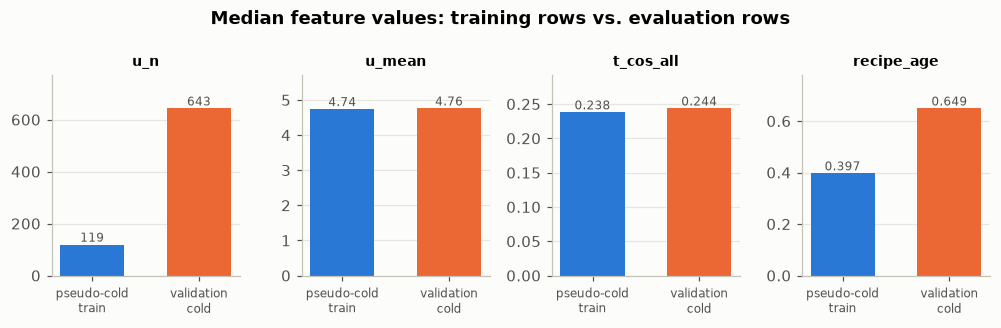

In [13]:
# content representations use recipe content only (no ratings), so they are built from all recipes
tag_vocab = top_vocab(recipes.tags, N_TAGS)
content = content_matrix(recipes, tag_vocab, top_vocab(recipes.ingredients, N_INGREDIENTS))
X_text = tfidf_matrix(recipes)
recipe_feats = recipe_features(recipes, tag_vocab)

def featurize(rows, history):
    # all features of `rows`, using only reviews in `history` dated before each row
    return build_features(rows, history, recipes, content, recipe_feats=recipe_feats, tfidf=X_text).astype(np.float32)

def training_set(history):
    rows = pseudo_cold_rows(history)                 # reviews on each recipe's first review day
    feats = featurize(rows, history)
    keep = (feats.u_n >= MIN_PRIOR).values           # user had >= 3 earlier ratings
    return rows[keep], feats[keep], training_weights(rows.user_id.values[keep])   # weights 1/sqrt(n_u)

train_rows, train_feats, train_w = training_set(train)
valid_feats = featurize(valid, train)
vc = (valid.cold == 1).values
print(f"pseudo-cold training rows: {len(train_rows):,} (5-star share {train_rows.y.mean():.1%}); validation cold rows: {vc.sum():,}")

compare_medians(train_feats[["u_n", "u_mean", "t_cos_all", "recipe_age"]].median(),
                  valid_feats.loc[vc, ["u_n", "u_mean", "t_cos_all", "recipe_age"]].median(),
                  ["pseudo-cold\ntrain", "validation\ncold"], "Median feature values: training rows vs. evaluation rows")

The training rows match the evaluation rows on the user's rating level and on content similarity. Two differences are expected: evaluation users have longer histories (they were active before 2013), and cold evaluation recipes are older at review time (median 0.65 vs. 0.40 years), because a first review usually comes soon after posting. The ablation in Section 4 checks that recipe age does not cause extrapolation problems.

### 3.3 Which features carry signal?

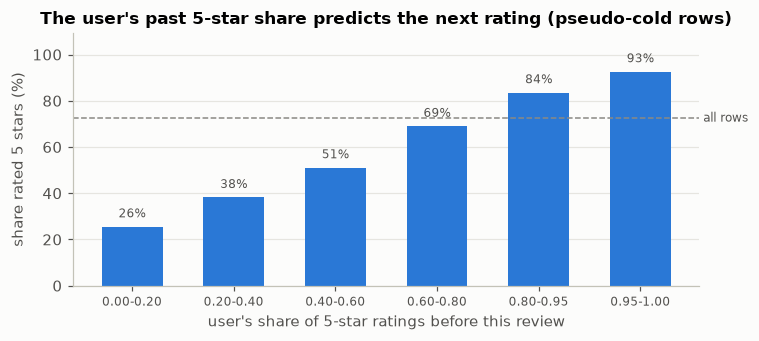

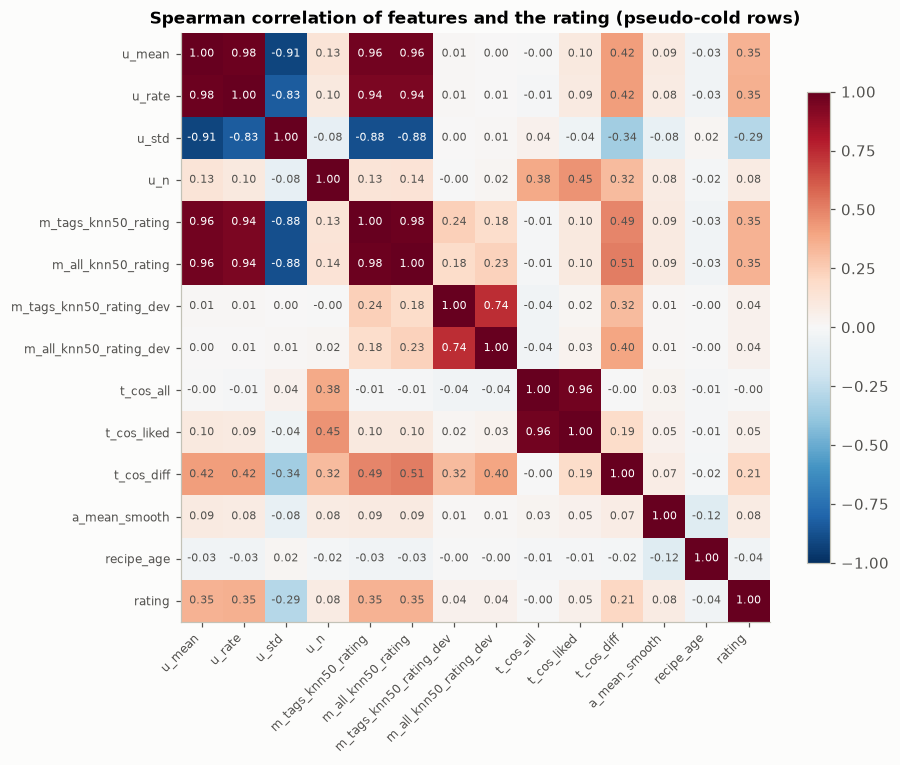

In [14]:
bins = pd.cut(train_feats.u_rate, [0, 0.2, 0.4, 0.6, 0.8, 0.95, 1.0], include_lowest=True)
share = train_rows.y.groupby(bins.values, observed=True).mean() * 100
fig, ax = plt.subplots(figsize=(7, 3.2))
bars(ax, [f"{max(b.left, 0):.2f}-{b.right:.2f}" for b in share.index], share.values, fmt="{:.0f}%",
       ref=train_rows.y.mean() * 100, ref_label="all rows", ylabel="share rated 5 stars (%)",
       title="The user's past 5-star share predicts the next rating (pseudo-cold rows)")
ax.set_xlabel("user's share of 5-star ratings before this review")
plt.tight_layout(); plt.show()

show = ["u_mean", "u_rate", "u_std", "u_n", "m_tags_knn50_rating", "m_all_knn50_rating", "m_tags_knn50_rating_dev",
        "m_all_knn50_rating_dev", "t_cos_all", "t_cos_liked", "t_cos_diff", "a_mean_smooth", "recipe_age"]
corr = train_feats[show].assign(rating=train_rows.rating.values).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.6, 7))
fig.colorbar(heatmap(ax, corr, title="Spearman correlation of features and the rating (pseudo-cold rows)"), ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

**The user's rating habit is the strongest signal**: users who rarely gave 5 stars before give 5 stars to a new recipe about a quarter of the time, users who almost always did about 93% of the time (bottom row of the heatmap: Spearman 0.35 for `u_mean`). The author's past ratings (`a_mean_smooth`, 0.08) and recipe content (in the EDA, e.g. crock-pot recipes and older recipes are rated slightly lower) have smaller but consistent effects.

The heatmap also exposed a **redundancy**: the k-NN features ("the user's mean rating on the 50 most similar past recipes", `m_*_knn50_rating`) correlate 0.96 with the user's overall mean, because a user's 50 nearest recipes are much of everything they rated. They repeat group B instead of describing the recipe. The main models therefore use them **relative to the user**: `*_knn{k}_rating_dev` = k-NN mean − user mean (and likewise for the 5-star share), which is uncorrelated with the user's mean (0.00–0.01), and `t_cos_diff` = similarity to the user's 5-star recipes − similarity to all their recipes. This leaves accuracy unchanged but makes feature importance honest: with the raw k-NN features the LightGBM model credited 44% of its split gain to group C and 38% to group B; with the relative ones it is 33% and 50%. What is left that is specific to the recipe is weak (0.02–0.04 with the rating, 0.21 for `t_cos_diff`), which already suggests the gains over the user-only baseline will be small.

### 3.4 Models

All models are fit on the pseudo-cold rows with the weights $1/\sqrt{n_u}$ and squared error, except B1, which is the course model fit on all training ratings.

| | Model | Information | Strengths / weaknesses |
|---|---|---|---|
| B0 | global mean rating | none | lower bound |
| B1 | $\alpha + \beta_u + \beta_i$, alternating closed-form updates, $\lambda$ = 10 | user and recipe ids | the standard rating model; on a cold recipe $\beta_i = 0$, so it reduces to $\alpha + \beta_u$. Latent factors $\gamma_u \cdot \gamma_i$ have the same problem: an unseen recipe's $\gamma_i$ is never learned (a BPR model scores every cold recipe identically) |
| B2 | ridge on 5 user-history features | user only | captures how generous each user is, but gives every recipe the same score for a user |
| B3 | ridge on TF-IDF similarity to the user's past / 5-star recipes | content only | personal taste, but ignores the user's rating level |
| **M1** | ridge on all groups A–D, $\lambda$ = 10,000 (median imputation + missing flags, log counts, standardization) | everything | interpretable coefficients; linear only |
| **M2** | LightGBM regression on all groups A–D: 63 leaves, ≥ 1,000 rows per leaf, 200 trees, learning rate 0.03 | everything | non-linear effects and interactions; less interpretable |

Hyperparameters were chosen by validation cold MSE: $\lambda$ for B1 over {1, 3, 10, 30}, for M1 over {1, …, 100,000}; for M2, tree size, rows per leaf and the number of trees over a 4 × 6 grid.

In [15]:
USER_COLS = ["u_n", "u_mean", "u_mean_smooth", "u_std", "u_rate"]
COUNT_COLS = ["u_n", "a_n", "a_recipes", "description_words"]
# the raw k-NN features and t_cos_liked are replaced by their versions relative to the user (Section 3.3)
REPLACED = [c for c in train_feats.columns if re.fullmatch(r"m_\w+_knn\d+(_rating)?", c)] + ["t_cos_liked"]
COLS = [c for c in train_feats.columns if c not in REPLACED]

def group_of(col):
    return "B" if col.startswith("u_") else "C" if col.startswith(("m_", "t_")) else "D" if col.startswith("a_") else "A"

def user_inputs(f):
    return f[USER_COLS].assign(u_n=np.log1p(f.u_n))

def text_inputs(f):
    liked = f.t_cos_liked.fillna(f.t_cos_all)          # user without 5-star history: fall back to all recipes
    return pd.DataFrame({"t_cos_all": f.t_cos_all.fillna(0), "t_cos_liked": liked.fillna(0)})

def all_inputs(f, cols=COLS):
    X = f[cols].copy()
    for c in set(COUNT_COLS) & set(cols):
        X[c] = np.log1p(X[c])
    return X.values

# every fit_* takes the training rows, their features, the weights and the review history,
# and returns predict(rows, feats) -> predicted rating (unclipped)
def fit_b0(rows, feats, w, history):
    mean = history.rating.mean()
    return lambda r, f: np.full(len(r), mean)

def fit_b1(rows, feats, w, history, lam=10, n_iter=30):
    u, i = history.user_id.astype("category"), history.recipe_id.astype("category")
    uc, ic, y = u.cat.codes.values, i.cat.codes.values, history.rating.values.astype(float)
    bu, bi = np.zeros(len(u.cat.categories)), np.zeros(len(i.cat.categories))
    n_u, n_i = np.bincount(uc, minlength=len(bu)), np.bincount(ic, minlength=len(bi))
    for _ in range(n_iter):
        alpha = (y - bu[uc] - bi[ic]).mean()
        bu = np.bincount(uc, y - alpha - bi[ic], len(bu)) / (lam + n_u)
        bi = np.bincount(ic, y - alpha - bu[uc], len(bi)) / (lam + n_i)
    bu, bi = pd.Series(bu, index=u.cat.categories), pd.Series(bi, index=i.cat.categories)
    return lambda r, f: alpha + bu.reindex(r.user_id).fillna(0).values + bi.reindex(r.recipe_id).fillna(0).values

def ridge(inputs, alpha):
    def fit(rows, feats, w, history):
        model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), Ridge(alpha=alpha))
        model.fit(inputs(feats), rows.rating.values, ridge__sample_weight=w)
        return lambda r, f: model.predict(inputs(f))
    return fit

LGB_BASE = dict(learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
                random_state=0, verbose=-1)
M2_PARAMS = dict(num_leaves=63, min_child_samples=1000, n_estimators=200)

def lightgbm(cols, **params):
    def fit(rows, feats, w, history):
        model = lgb.LGBMRegressor(**LGB_BASE, **params).fit(feats[cols].values, rows.rating.values, sample_weight=w)
        return lambda r, f: model.predict(f[cols].values)
    return fit

MODELS = {"B0 global mean": fit_b0,
          "B1 bias model": fit_b1,
          "B2 user features": ridge(user_inputs, alpha=1.0),
          "B3 TF-IDF cosine": ridge(text_inputs, alpha=1.0),
          "M1 ridge": ridge(all_inputs, alpha=10_000),
          "M2 LightGBM": lightgbm(COLS, **M2_PARAMS)}
B2 = "B2 user features"
print(f"{len(COLS)} features:", pd.Series([group_of(c) for c in COLS]).value_counts().sort_index().to_dict())

384 features: {'A': 321, 'B': 6, 'C': 53, 'D': 4}


## 4. Evaluation

**Protocol.** Models are first fit on the training split and evaluated on the validation cold rows (this is where the hyperparameters and the feature-group ablation are decided). They are then refit on **train + validation** and evaluated **once** on the 4,099 test cold rows.

**Why these metrics.** MSE is the main metric because it is the loss we train on and the course's rating-prediction metric, but on this data it is dominated by the rare low ratings, so we add AUC for `rating == 5` (can the model order reviews from least to most likely 5 stars?) and Hit@10 / NDCG@10 (can it pick, *for one user*, the recipe they will love among 100 new recipes?). A model that only knows the user gives every candidate the same score, so its Hit@10 is exactly the random 0.10. All intervals are 95% bootstraps that resample **users** (the top 5 users contribute 11–15% of the cold rows), and comparisons are paired on the same bootstrap samples.

The evaluation code: metrics with user-level bootstrap intervals, paired comparisons on the same bootstrap samples, and the candidate lists for Hit@10 / NDCG@10 (ties are counted at their expected rank, so a constant score gets exactly the random value).

In [16]:
N_BOOT = 1000

def _mse(y, pred):
    return np.mean((y - pred) ** 2)

def _user_groups(users):
    return list(pd.Series(np.arange(len(users))).groupby(np.asarray(users)).indices.values())

def _bootstrap(y, scores, users, metric, n_boot=N_BOOT, seed=0):
    """metric of each score array on the same user-level bootstrap samples: array (n_boot, len(scores))."""
    rng = np.random.default_rng(seed)
    groups = _user_groups(users)
    out = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[g] for g in rng.integers(len(groups), size=len(groups))])
        if metric is roc_auc_score and y[idx].min() == y[idx].max():
            continue
        out.append([metric(y[idx], s[idx]) for s in scores])
    return np.array(out)

def _paired(y, score_a, score_b, users, metric, n_boot):
    a, b = np.asarray(score_a, float), np.asarray(score_b, float)
    diff = np.diff(_bootstrap(y, [b, a], users, metric, n_boot), axis=1)[:, 0]   # metric(a) - metric(b)
    lo, hi = np.percentile(diff, [2.5, 97.5])
    return metric(y, a) - metric(y, b), lo, hi, diff

def evaluate_rating(y, pred, users, n_boot=N_BOOT):
    """MSE with 95% user-bootstrap CI, RMSE and MAE. Predictions are clipped to the rating range [1, 5]."""
    y, pred = np.asarray(y, float), np.clip(np.asarray(pred, float), 1, 5)
    lo, hi = np.percentile(_bootstrap(y, [pred], users, _mse, n_boot)[:, 0], [2.5, 97.5])
    mse = _mse(y, pred)
    return {"MSE": mse, "CI low": lo, "CI high": hi, "RMSE": np.sqrt(mse),
            "MAE": np.mean(np.abs(y - pred)), "rows": len(y)}

def compare_rating(y, pred_a, pred_b, users, n_boot=N_BOOT):
    """Paired bootstrap of MSE(a) - MSE(b) (negative = a is better) and share of samples where a is not better."""
    y = np.asarray(y, float)
    d, lo, hi, diff = _paired(y, np.clip(pred_a, 1, 5), np.clip(pred_b, 1, 5), users, _mse, n_boot)
    return {"MSE diff": d, "CI low": lo, "CI high": hi, "p(a >= b)": (diff >= 0).mean()}

def evaluate(y, score, users, n_boot=N_BOOT, is_prob=None):
    """AUC with 95% user-bootstrap CI, and log loss (only for scores that are probabilities;
    by default, scores inside [0, 1])."""
    y, score = np.asarray(y), np.asarray(score, dtype=float)
    lo, hi = np.percentile(_bootstrap(y, [score], users, roc_auc_score, n_boot)[:, 0], [2.5, 97.5])
    if is_prob is None:
        is_prob = score.min() >= 0 and score.max() <= 1
    return {"AUC": roc_auc_score(y, score), "CI low": lo, "CI high": hi,
            "log loss": log_loss(y, np.clip(score, 1e-6, 1 - 1e-6)) if is_prob else np.nan,
            "rows": len(y)}

def compare(y, score_a, score_b, users, n_boot=N_BOOT):
    """Paired bootstrap of AUC(a) - AUC(b): difference, 95% CI, and share of samples where a <= b."""
    d, lo, hi, diff = _paired(np.asarray(y), score_a, score_b, users, roc_auc_score, n_boot)
    return {"AUC diff": d, "CI low": lo, "CI high": hi, "p(a <= b)": (diff <= 0).mean()}

def sample_candidates(pos_rows, pool, reviewed, submitted, n_neg=99, seed=0):
    """Candidate lists for ranking: each positive row's recipe plus n_neg recipes from `pool` that the user
    never reviewed (`reviewed`: user -> set of recipe ids) and that were already submitted at the row's date."""
    rng = np.random.default_rng(seed)
    pool = np.asarray(pool)
    pool_submitted = submitted.reindex(pool).values
    out = []
    for g, row in enumerate(pos_rows.itertuples()):
        ok = pool[(pool_submitted < np.datetime64(row.date)) & ~np.isin(pool, list(reviewed.get(row.user_id, ())))]
        negs = rng.choice(ok, size=min(n_neg, len(ok)), replace=False)
        out.append(pd.DataFrame({"group": g, "user_id": row.user_id, "date": row.date,
                                 "recipe_id": np.concatenate([[row.recipe_id], negs]),
                                 "is_pos": np.r_[1, np.zeros(len(negs), int)]}))
    return pd.concat(out, ignore_index=True)

def ranking_metrics(cands, score, k=10):
    """Hit@k and NDCG@k per candidate list (one positive each). Ties are broken at random, so the value is
    the expectation over the positive's possible ranks: a constant score gets Hit@10 = 10 / list length."""
    df = cands[["group", "is_pos"]].assign(s=np.asarray(score, float))
    pos = df[df.is_pos == 1].set_index("group").s
    neg = df[df.is_pos == 0]
    above = (neg.s.values > pos.reindex(neg.group).values)
    tied = (neg.s.values == pos.reindex(neg.group).values)
    g = pd.Series(above).groupby(neg.group.values).sum().reindex(pos.index, fill_value=0).values
    t = pd.Series(tied).groupby(neg.group.values).sum().reindex(pos.index, fill_value=0).values
    hit, ndcg = np.zeros(len(pos)), np.zeros(len(pos))
    for j, (gj, tj) in enumerate(zip(g, t)):
        ranks = np.arange(gj + 1, gj + tj + 2)              # the positive is equally likely at each tied rank
        top = ranks[ranks <= k]
        hit[j] = len(top) / len(ranks)
        ndcg[j] = (1 / np.log2(top + 1)).sum() / len(ranks)
    return pd.DataFrame({"group": pos.index, f"Hit@{k}": hit, f"NDCG@{k}": ndcg})

def mean_ci(values, users, n_boot=N_BOOT, seed=0):
    """Mean of per-row values with a 95% user-bootstrap CI."""
    values = np.asarray(values, float)
    boots = _bootstrap(values, [values], users, lambda y, s: s.mean(), n_boot, seed)[:, 0]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return values.mean(), lo, hi

B1 on validation cold rows: at most 1 distinct prediction(s) per user


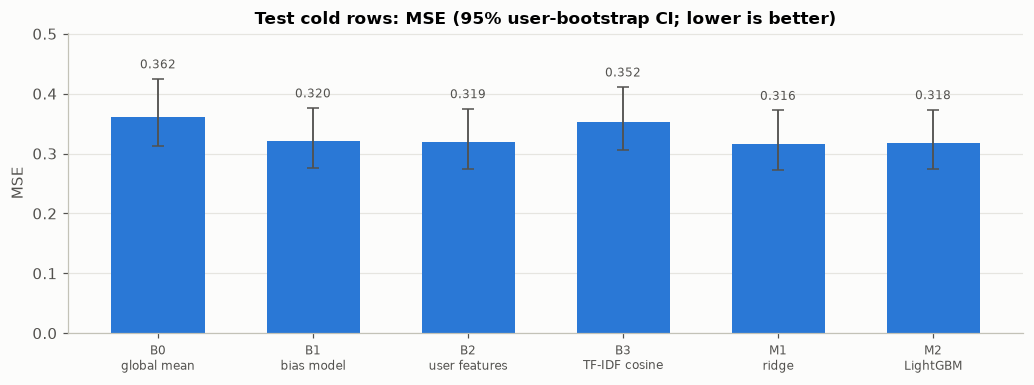

                     MSE  CI low  CI high    RMSE     MAE
B0 global mean    0.3617  0.3122   0.4246  0.6014  0.4533
B1 bias model     0.3204  0.2752   0.3761  0.5660  0.3988
B2 user features  0.3187  0.2742   0.3748  0.5645  0.3760
B3 TF-IDF cosine  0.3519  0.3055   0.4110  0.5932  0.4566
M1 ridge          0.3161  0.2724   0.3720  0.5623  0.3953
M2 LightGBM       0.3178  0.2746   0.3732  0.5638  0.3862


In [17]:
# validation: fit on train, predict the validation rows
y_valid, users_valid = valid.rating.values.astype(float), valid.user_id.values
val_pred = {name: np.clip(fit(train_rows, train_feats, train_w, train)(valid, valid_feats), 1, 5)
            for name, fit in MODELS.items()}
per_user = pd.Series(val_pred["B1 bias model"][vc]).groupby(users_valid[vc]).nunique().max()
print(f"B1 on validation cold rows: at most {per_user} distinct prediction(s) per user")

# test: refit on train + validation, predict the test rows once
full = pd.concat([train, valid], ignore_index=True)
final_rows, final_feats, final_w = training_set(full)
test_feats = featurize(test, full)
tc = (test.cold == 1).values
y_test, users_test = test.rating.values.astype(float), test.user_id.values
fitted = {name: fit(final_rows, final_feats, final_w, full) for name, fit in MODELS.items()}
test_pred = {name: np.clip(predict(test, test_feats), 1, 5) for name, predict in fitted.items()}

test_mse = pd.DataFrame({name: evaluate_rating(y_test[tc], p[tc], users_test[tc]) for name, p in test_pred.items()}).T
fig, ax = plt.subplots(figsize=(9.5, 3.6))
bars(ax, test_mse.index, test_mse["MSE"], test_mse["CI low"], test_mse["CI high"],
       title="Test cold rows: MSE (95% user-bootstrap CI; lower is better)", ylabel="MSE")
plt.tight_layout(); plt.show()
print(test_mse[["MSE", "CI low", "CI high", "RMSE", "MAE"]].round(4).to_string())

**Main result.** Knowing the user is what matters for MSE: B1 and B2 lower the MSE from 0.362 (global mean) to about 0.32, and on a cold recipe the course's bias model B1 is exactly $\alpha + \beta_u$ (one prediction per user). Content alone (B3) is much worse, because it does not know how generous the user is. The main models M1 and M2 are the most accurate, but only slightly ahead of B2. The paired comparison tells whether that difference is real:

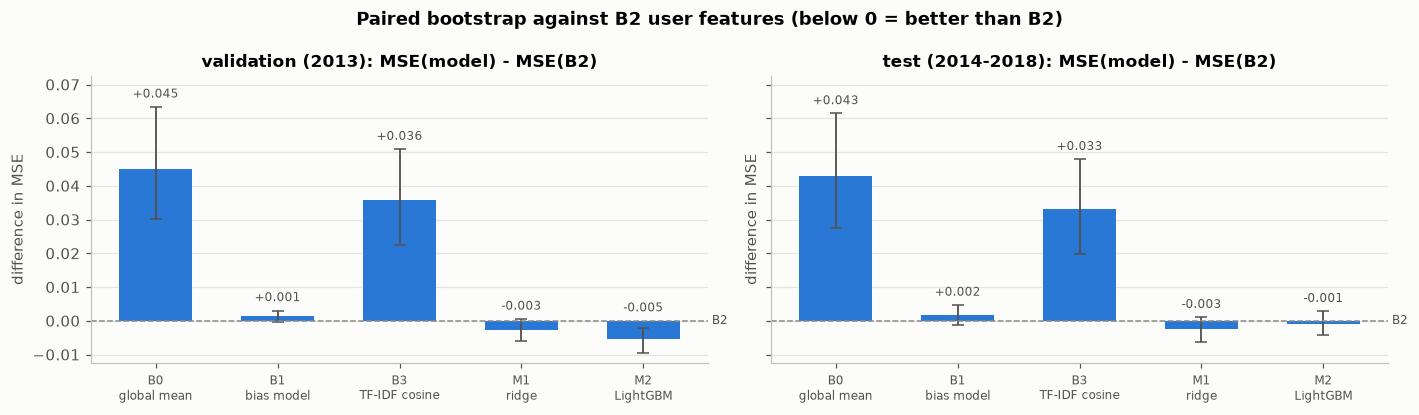

validation (2013): B0 global mean +0.0451 [+0.0300, +0.0633]; B1 bias model +0.0014 [-0.0004, +0.0030]; B3 TF-IDF cosine +0.0358 [+0.0226, +0.0508]; M1 ridge -0.0026 [-0.0060, +0.0005]; M2 LightGBM -0.0053 [-0.0095, -0.0021]
test (2014-2018): B0 global mean +0.0430 [+0.0274, +0.0614]; B1 bias model +0.0017 [-0.0013, +0.0047]; B3 TF-IDF cosine +0.0332 [+0.0199, +0.0479]; M1 ridge -0.0025 [-0.0063, +0.0011]; M2 LightGBM -0.0008 [-0.0041, +0.0028]


In [18]:
def paired_vs_b2(y, preds, users, mask):
    return pd.DataFrame({name: compare_rating(y[mask], p[mask], preds[B2][mask], users[mask])
                         for name, p in preds.items() if name != B2}).T

paired = {"validation (2013)": paired_vs_b2(y_valid, val_pred, users_valid, vc),
          "test (2014-2018)": paired_vs_b2(y_test, test_pred, users_test, tc)}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (split, t) in zip(axes, paired.items()):
    bars(ax, t.index, t["MSE diff"], t["CI low"], t["CI high"], ref=0, ref_label="B2", fmt="{:+.3f}",
           title=f"{split}: MSE(model) - MSE(B2)", ylabel="difference in MSE")
fig.suptitle("Paired bootstrap against B2 user features (below 0 = better than B2)", fontweight="bold")
plt.tight_layout(); plt.show()
for split, t in paired.items():
    print(split + ":", "; ".join(f"{n} {r['MSE diff']:+.4f} [{r['CI low']:+.4f}, {r['CI high']:+.4f}]" for n, r in t.iterrows()))

On validation, M2 is **significantly** better than B2 (about 1.7% lower MSE, interval below 0) and M1 is better on average but not significantly. On test, both remain slightly better than B2, but the intervals contain 0: **the validation gain of M2 is not confirmed on the test split**. B1 and B2 are indistinguishable, as expected, since both only know the user.

### 4.1 Which feature groups help? (validation)

Each model is refit on subsets of the groups, always including B (without it a model cannot know how generous the user is). The last setting drops `recipe_age`, the feature whose distribution differs most between training and evaluation rows.

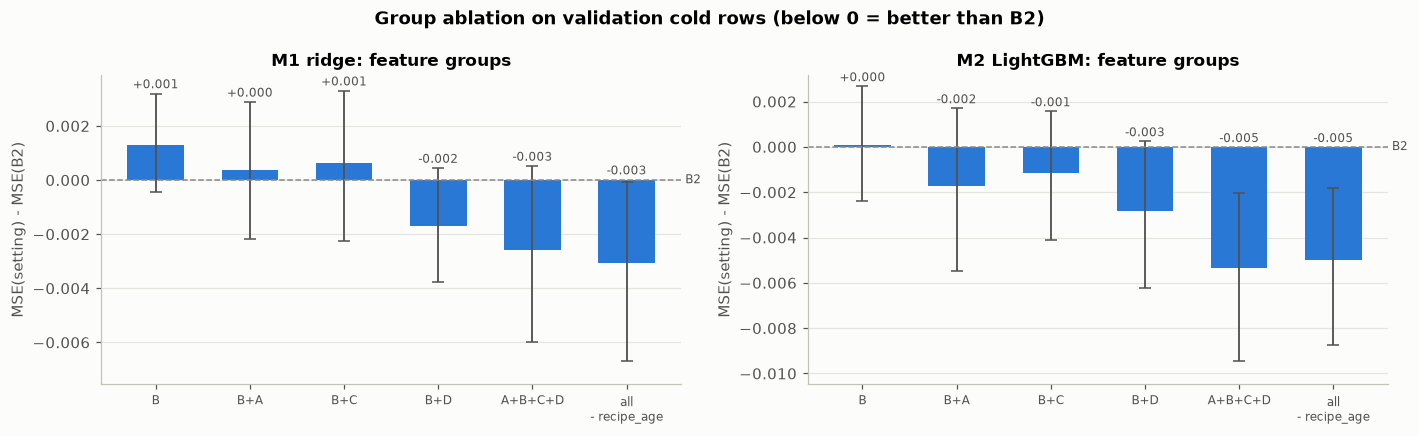

In [19]:
SETTINGS = {"B": "B", "B+A": "AB", "B+C": "BC", "B+D": "BD", "A+B+C+D": "ABCD"}
setting_cols = {name: [c for c in COLS if group_of(c) in g] for name, g in SETTINGS.items()}
setting_cols["all - recipe_age"] = [c for c in COLS if c != "recipe_age"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, model in zip(axes, ["M1 ridge", "M2 LightGBM"]):
    rows = {}
    for name, cols in setting_cols.items():
        fit = ridge(lambda f, c=cols: all_inputs(f, c), 10_000) if model == "M1 ridge" else lightgbm(cols, **M2_PARAMS)
        p = np.clip(fit(train_rows, train_feats, train_w, train)(valid, valid_feats), 1, 5)
        rows[name] = compare_rating(y_valid[vc], p[vc], val_pred[B2][vc], users_valid[vc])
    t = pd.DataFrame(rows).T
    bars(ax, t.index, t["MSE diff"], t["CI low"], t["CI high"], ref=0, ref_label="B2", fmt="{:+.3f}",
           title=f"{model}: feature groups", ylabel="MSE(setting) - MSE(B2)")
fig.suptitle("Group ablation on validation cold rows (below 0 = better than B2)", fontweight="bold")
plt.tight_layout(); plt.show()

No single group added to the user features moves the MSE significantly; the author group D gives the largest single gain. M2 becomes significantly better than B2 only with all groups together, which suggests that the trees use **interactions between groups** (e.g. a strict user *and* a recipe unlike anything they loved) rather than any one group. Dropping `recipe_age` does not hurt, so the age shift between training and evaluation rows causes no extrapolation problem.

### 4.2 Where do the errors come from?

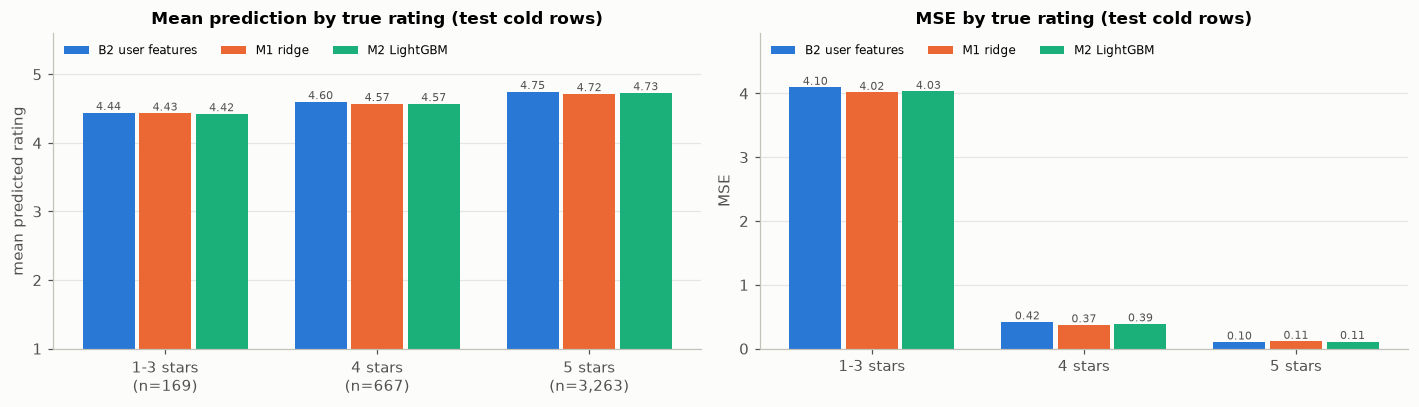

In [20]:
SHOW = [B2, "M1 ridge", "M2 LightGBM"]
yc = y_test[tc]
levels = {"1-3 stars": (yc <= 3), "4 stars": (yc == 4), "5 stars": (yc == 5)}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
grouped_bars(axes[0], [f"{k}\n(n={m.sum():,})" for k, m in levels.items()],
               {n: [test_pred[n][tc][m].mean() for m in levels.values()] for n in SHOW},
               "mean predicted rating", "Mean prediction by true rating (test cold rows)")
axes[0].set_ylim(1, 5.6)
grouped_bars(axes[1], list(levels), {n: [((test_pred[n][tc] - yc)[m] ** 2).mean() for m in levels.values()] for n in SHOW},
               "MSE", "MSE by true rating (test cold rows)")
plt.tight_layout(); plt.show()

**The bottleneck is the rare low ratings.** Every model predicts about 4.4 stars for reviews that ended at 1–3 stars, and those 169 rows (4%) carry most of the squared error. The main models gain a little on the 1–3 and 4-star rows and lose a little on the 5-star rows, which is why the overall gain is small. Nothing in a user's history or a recipe's content reliably announces that this user will dislike this new recipe.

### 4.3 Ranking: user information vs. content information

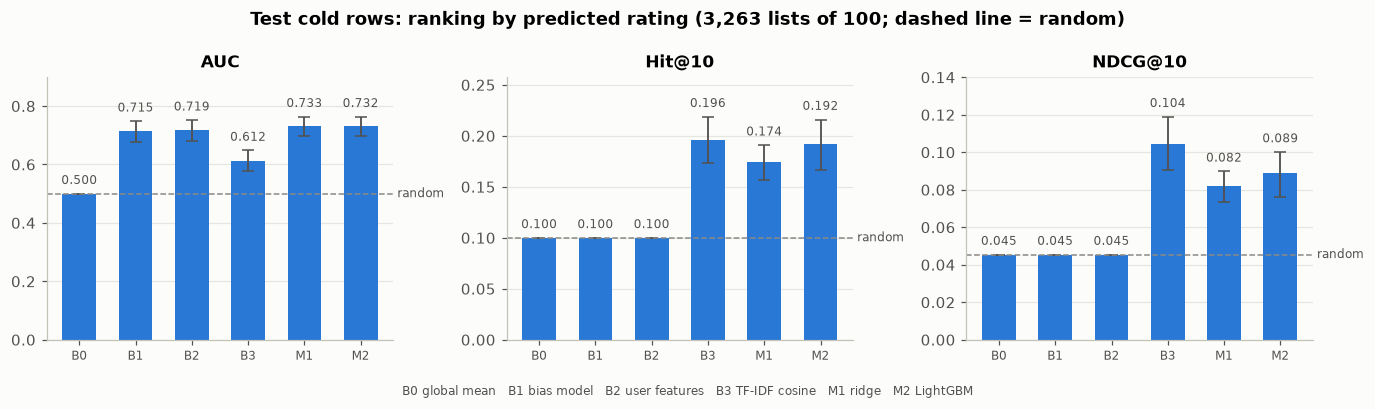

In [21]:
reviewed = pd.concat([train, valid, test]).groupby("user_id").recipe_id.agg(set).to_dict()
cold_pool = recipes.index[~recipes.index.isin(full.recipe_id)]          # recipes with no reviews in train + validation
positives = test[tc & (test.rating == 5)]
cands = sample_candidates(positives, cold_pool, reviewed, recipes.submitted)   # 1 positive + 99 cold negatives each
cand_feats = featurize(cands, full)

rank = {}
for name, predict in fitted.items():
    auc = evaluate((yc == 5).astype(int), test_pred[name][tc], users_test[tc], is_prob=False)
    per_list = ranking_metrics(cands, predict(cands, cand_feats))     # unclipped scores: no artificial ties at 5
    hit = mean_ci(per_list["Hit@10"], positives.user_id.values)
    ndcg = mean_ci(per_list["NDCG@10"], positives.user_id.values)
    rank[name] = {"AUC": auc["AUC"], "AUC low": auc["CI low"], "AUC high": auc["CI high"],
                  "Hit@10": hit[0], "Hit@10 low": hit[1], "Hit@10 high": hit[2],
                  "NDCG@10": ndcg[0], "NDCG@10 low": ndcg[1], "NDCG@10 high": ndcg[2]}
rank = pd.DataFrame(rank).T
random_ndcg = ranking_metrics(cands, np.zeros(len(cands)))["NDCG@10"].mean()
metric_bars(rank, ["AUC", "Hit@10", "NDCG@10"], refs={"AUC": 0.5, "Hit@10": 0.1, "NDCG@10": random_ndcg},
              suptitle=f"Test cold rows: ranking by predicted rating ({len(positives):,} lists of 100; dashed line = random)")

The two kinds of metric reward different information:

- **AUC** compares reviews of *different* users, so knowing who is generous is enough: B1 and B2 reach 0.72, content-only B3 only 0.61.
- **Hit@10 / NDCG@10** rank recipes *for one user*, so user information is useless: B0–B2 give every candidate the same score and are exactly random (0.10). Only content helps: B3 doubles Hit@10 to 0.20.

**M1 and M2 are the only models that do well on both.** They have the highest AUC (0.73 vs. 0.72 for B2; the paired difference, about +0.01, is significant, see 4.5) and a Hit@10 that is not significantly different from B3 (M2 0.19, M1 0.17). B3 keeps a small edge on NDCG@10 (significant for M1): ranking asks *which* recipe the user will review, which is exactly what text similarity measures, while M1 and M2 are trained to predict *how high* the rating will be.

So the content features do carry information about the user's taste; they show up in ranking and in AUC, but are too weak relative to the squared error of the rare low ratings to show up in MSE.

### 4.4 Users with short histories, and warm recipes

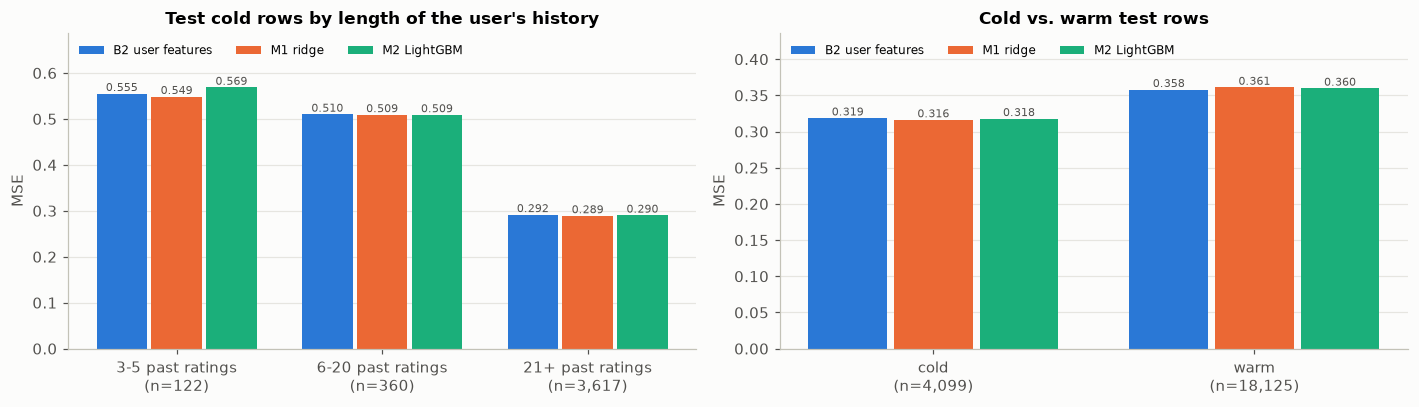

In [22]:
u_n = test_feats.u_n.values
hist = {"3-5": (u_n <= 5), "6-20": (u_n > 5) & (u_n <= 20), "21+": (u_n > 20)}
sq = {n: (test_pred[n] - y_test) ** 2 for n in SHOW}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
grouped_bars(axes[0], [f"{k} past ratings\n(n={(tc & m).sum():,})" for k, m in hist.items()],
               {n: [sq[n][tc & m].mean() for m in hist.values()] for n in SHOW}, "MSE",
               "Test cold rows by length of the user's history", fmt="{:.3f}")
grouped_bars(axes[1], [f"cold\n(n={tc.sum():,})", f"warm\n(n={(~tc).sum():,})"],
               {n: [sq[n][tc].mean(), sq[n][~tc].mean()] for n in SHOW}, "MSE", "Cold vs. warm test rows", fmt="{:.3f}")
plt.tight_layout(); plt.show()

Users with only 3–5 earlier ratings are the hardest (MSE about 0.55), and there the linear M1 is the best model while M2 is the worst: with little user history, content features matter more, and the linear model uses them more robustly. For users with 21+ ratings (88% of rows) the three models are within 0.003. Cold and warm rows get similar errors (warm test rows are slightly harder in this period), as they should: none of the models uses rating statistics of the recipe, so a warm recipe is treated exactly like a cold one. Using the ratings a warm recipe already has would be a different (and easier) task.

### 4.5 Supplementary task: P(rating == 5)

The same training rows and features with a binary target and log loss: B2 becomes a logistic regression on the user features, and M2 a LightGBM classifier (63 leaves, ≥ 1,000 rows per leaf, 700 trees, chosen by validation AUC). We compare them with the rating models, whose predicted rating is used as the score.

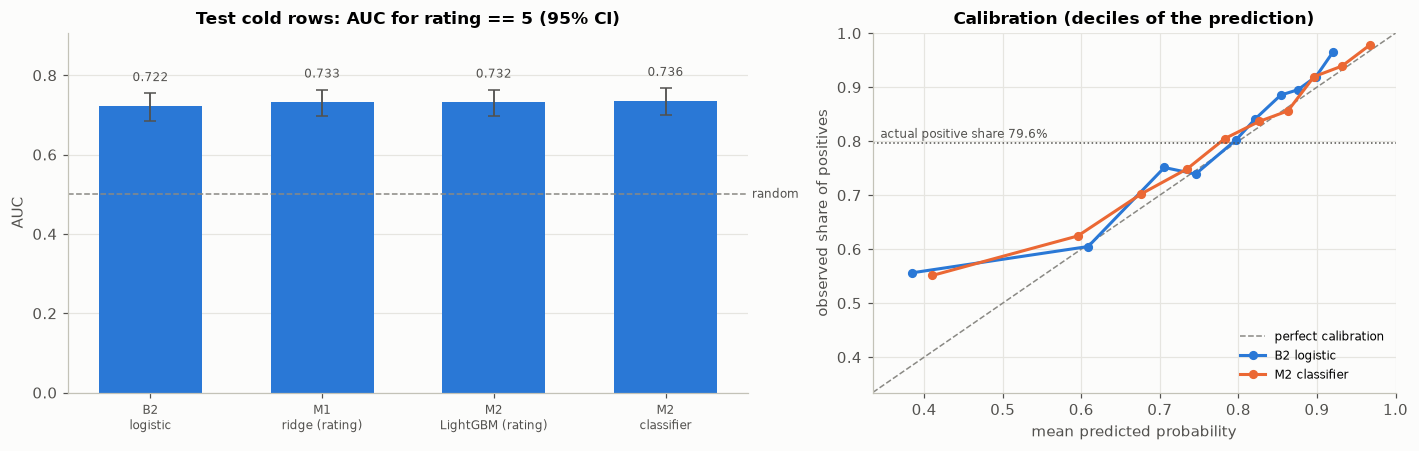

M1 ridge (rating) - B2: AUC +0.0108 [+0.0025, +0.0210]


M2 LightGBM (rating) - B2: AUC +0.0098 [+0.0015, +0.0195]


M2 classifier - B2: AUC +0.0138 [+0.0043, +0.0272]


M2 classifier - M2 LightGBM (rating): AUC +0.0039 [-0.0028, +0.0114]
log loss: B2 logistic 0.4615, M2 classifier 0.4497 | 5-star share: training rows 72.6%, test cold rows 79.6%


In [23]:
def fit_b2_logistic(rows, feats, w):
    cols = ["u_n", "u_rate", "u_rate_smooth", "u_mean", "u_std"]
    inputs = lambda f: f[cols].assign(u_n=np.log1p(f.u_n))
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(inputs(feats), rows.y, logisticregression__sample_weight=w)
    return lambda f: model.predict_proba(inputs(f))[:, 1]

def fit_m2_classifier(rows, feats, w):
    model = lgb.LGBMClassifier(**LGB_BASE, num_leaves=63, min_child_samples=1000, n_estimators=700)
    model.fit(feats[COLS].values, rows.y.values, sample_weight=w)
    return lambda f: model.predict_proba(f[COLS].values)[:, 1]

y5 = (yc == 5).astype(int)
scores = {"B2 logistic": fit_b2_logistic(final_rows, final_feats, final_w)(test_feats)[tc],
          "M1 ridge (rating)": fitted["M1 ridge"](test, test_feats)[tc],
          "M2 LightGBM (rating)": fitted["M2 LightGBM"](test, test_feats)[tc],
          "M2 classifier": fit_m2_classifier(final_rows, final_feats, final_w)(test_feats)[tc]}
auc = pd.DataFrame({n: evaluate(y5, s, users_test[tc]) for n, s in scores.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
bars(axes[0], auc.index, auc["AUC"], auc["CI low"], auc["CI high"], ref=0.5,
       title="Test cold rows: AUC for rating == 5 (95% CI)", ylabel="AUC")
calibration(axes[1], y5, {n: scores[n] for n in ["B2 logistic", "M2 classifier"]},
              title="Calibration (deciles of the prediction)")
plt.tight_layout(); plt.show()

for n in list(scores)[1:]:
    d = compare(y5, scores[n], scores["B2 logistic"], users_test[tc])
    print(f"{n} - B2: AUC {d['AUC diff']:+.4f} [{d['CI low']:+.4f}, {d['CI high']:+.4f}]")
d = compare(y5, scores["M2 classifier"], scores["M2 LightGBM (rating)"], users_test[tc])
print(f"M2 classifier - M2 LightGBM (rating): AUC {d['AUC diff']:+.4f} [{d['CI low']:+.4f}, {d['CI high']:+.4f}]")
print("log loss:", ", ".join(f"{n} {auc.loc[n, 'log loss']:.4f}" for n in ["B2 logistic", "M2 classifier"]),
      f"| 5-star share: training rows {final_rows.y.mean():.1%}, test cold rows {y5.mean():.1%}")

- **AUC detects what MSE could not.** All three main models are significantly better than B2 in AUC (about +0.01), although the same rating models were not significantly better in MSE.
- **The choice of target hardly matters.** The classifier trained on "5 stars or not" and the regressor trained on the 1–5 rating rank the test reviews equally well (difference within noise), so choosing the rating as the main task costs nothing in ranking ability. The classifier also has the lowest log loss.
- **Probabilities are slightly too low.** In almost every decile the observed 5-star share is above the prediction (dotted line: the actual test 5-star share). Pseudo-cold training rows are 5 stars 72.6% of the time, the test cold rows 79.6%: first reviews are a little harsher than later ones. The ordering is unaffected; an intercept shift fit on the validation rows would correct the level.

## 5. Related work

**The dataset.** Majumder et al. (2019), *Generating Personalized Recipes from Historical User Preferences* (EMNLP), collected these Food.com reviews to generate recipe text conditioned on a user's past recipes, not to predict ratings. Their split holds out each user's most recent interactions but keeps the rest; as shown in Section 2.1, for 82.7% of test users the training file still contains later reviews, so user histories built from it see the future. Results on that split are therefore not comparable with ours, and we re-split by time.

**Rating prediction from ids.** The course's bias model and its latent-factor extension (Koren, Bell & Volinsky 2009, *Matrix Factorization Techniques for Recommender Systems*) learn one parameter vector per item from its ratings, and BPR (Rendle et al. 2009) does the same for implicit feedback. Both give no information about an item without ratings, which our B1 (reduces to $\alpha + \beta_u$) and a BPR model (identical scores for all cold recipes) confirm.

**Cold-start.** Schein et al. (2002), *Methods and Metrics for Cold-Start Recommendations* (SIGIR), framed the item cold-start problem and combined content with collaborative information in one probabilistic model; they also argued for evaluating cold-start separately, as we do with the `cold` rows. Factorization machines (Rendle 2010, ICDM) generalize matrix factorization to arbitrary features, so an item is represented by its attributes instead of its id; LightFM (Kula 2015) applies this to cold-start recommendation by representing users and items as sums of feature embeddings. DropoutNet (Volkovs, Yu & Poutanen 2017, NeurIPS) trains a neural recommender with the preference input randomly dropped so that it learns to rely on content when ratings are missing.

**Our approach** is closest in spirit to these hybrid models, but simpler: we turn the user's history and the recipe's content into explicit, time-aware features and fit a supervised model on **pseudo-cold** rows (first-day reviews), whose conditions match the evaluation. Like the literature, we find that content mainly helps *ranking* new items for a user; unlike most papers, we evaluate on a strict time split with user-level confidence intervals, which shows how small the gains in rating error are once the user's own rating level is known. A factorization machine (Rendle 2010) over the same features would be the natural next model.

## 6. Conclusion

- **Task.** Predict the rating a user gives a recipe with no ratings in the training data, on a strict time split of Food.com (4,099 cold test reviews).
- **The user's rating level carries most of the signal.** A ridge regression on five user-history features (B2) already reaches a test MSE of 0.319 vs. 0.362 for the global mean; the course's bias model reduces to exactly this information on cold recipes.
- **Content and author information add a small, real signal.** M1 (ridge) and M2 (LightGBM) on all features are the only models that are both as accurate as B2 and able to rank new recipes for a user (Hit@10 about twice random, close to the content-only B3). Their AUC is significantly higher than B2's; their test MSE gain (0.3–0.8%) is not significant.
- **The limit is the rare low rating.** Reviews that ended at 1–3 stars are predicted at about 4.4 by every model. Predicting that a user will dislike a new recipe remains unsolved with this information.